# Evolutionary feature selection for postpartum hyperketonemia

CSE/ECE 848 final project. The clinical task is to predict which dairy cows will develop postpartum hyperketonemia (HYK) using only information available before calving. An earlier analysis in this lab compared classifiers on 70 prepartum features and then picked a subset with greedy forward selection. That selector adds one feature at a time and never removes one, and the subset was scored on the same cross-validation that chose it.

This notebook does two things. First it rebuilds the classifier comparison, so there is a result obtained without evolutionary computation. Then it searches the same 70 features with a genetic algorithm written in this notebook (NSGA-II, plus a single-objective GA and a fixed-size GA) and compares those subsets with greedy selection, L1 regularization, coefficient ranking, and random search. The comparison that matters is nested: each selector is allowed to see only the training cows in an outer fold, and the held-out cows are scored once.

## 1. Setup

Imports, paths, and the experiment settings live in one cell so a rerun is reproducible. `FAST` is on only for a smoke test. The submitted run has it off. Median imputation is used inside every training fold instead of k-nearest-neighbor imputation. It is still fit on training rows only. On a four-feature check the two imputers changed leave-one-out PR-AUC by about 0.002, and median imputation keeps the evolutionary loop fast enough to run repeated searches.

In [1]:
import json
import os
import time
import warnings
from pathlib import Path

import matplotlib


def _in_notebook():
    try:
        from IPython import get_ipython
        shell = get_ipython()
        return shell is not None and shell.__class__.__name__ == "ZMQInteractiveShell"
    except Exception:
        return False


if not _in_notebook():
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import LeaveOneOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "analysis.py").exists() and (ROOT / "CSE848_Evolutionary_Feature_Selection" / "analysis.py").exists():
    ROOT = ROOT / "CSE848_Evolutionary_Feature_Selection"
OUT = ROOT / "outputs"
OUT.mkdir(parents=True, exist_ok=True)

DATA_CANDIDATES = [
    ROOT.parent / "Dataset_metabolic_ac.xlsx",
    ROOT / "Dataset_metabolic_ac.xlsx",
    Path(r"d:\DRIVE Lab\metabolic_ketosis_prediction\Dataset_metabolic_ac.xlsx"),
]
DATA_PATH = next(p for p in DATA_CANDIDATES if p.exists())

SEED = 42
FAST = os.environ.get("EC_FAST", "0") == "1"

# Search settings. The full run is what the report uses.
POP_SIZE = 8 if FAST else 48
N_GEN = 1 if FAST else 30
N_RUNS = 1 if FAST else 3
NESTED_POP = 6 if FAST else 32
NESTED_GEN = 1 if FAST else 15
N_OUTER = 5
PENALTY_SIZE = 0.012
PENALTY_WEEK = 0.02
MUTATION_RATE = None  # set after p is known, default 1/p
CROSSOVER_RATE = 0.9
MAX_FORWARD_STEPS = 8
FORWARD_TOL = 0.002

WEEK_COLORS = {
    "PreP-3": "#2E86AB",
    "PreP-2": "#27AE60",
    "PreP-1": "#E67E22",
    "Slope": "#C0392B",
    "Management": "#8E44AD",
}
NAVY = "#1A3A5C"
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.grid": True,
    "grid.color": "#ECEFF1",
    "grid.linewidth": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "DejaVu Sans",
    "font.size": 11,
})

def log(msg):
    text = str(msg)
    try:
        print(text, flush=True)
    except UnicodeEncodeError:
        print(text.encode("ascii", "replace").decode("ascii"), flush=True)

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / name, dpi=160, bbox_inches="tight")
    if _in_notebook():
        from IPython.display import display
        display(fig)
    plt.close(fig)
    log(f"saved {name}")

log(f"FAST={FAST}  data={DATA_PATH.name}  out={OUT}")

FAST=False  data=Dataset_metabolic_ac.xlsx  out=D:\DRIVE Lab\metabolic_ketosis_prediction\CSE848_Evolutionary_Feature_Selection\outputs


## 2. Cohort and outcome

One row will represent one cow. A cow is HYK-positive if either postpartum test was positive. Postpartum measurements are never used as predictors. With 18 positive cows out of 132, accuracy is a poor target: a classifier that calls every cow negative is already 86% accurate and detects nobody. PR-AUC is the primary metric because its no-skill value equals the prevalence (0.136), so a result is easy to read as enrichment over chance.

In [2]:
df = pd.read_excel(DATA_PATH)
log(f"Raw table: {df.shape[0]} rows x {df.shape[1]} columns")

pp1_pos = df["PP1 ketotic?"].astype(str).str.strip().str.lower().eq("yes")
pp2_pos = df["PP2 ketotic?"].astype(str).str.strip().str.lower().eq("yes")
y_series = (pp1_pos | pp2_pos).astype(int)
y_series.name = "HYK_positive"
log(
    f"Outcome: {int(y_series.sum())} HYK+ | {int((y_series == 0).sum())} HYK- | "
    f"prevalence = {float(y_series.mean()):.3f}"
)

Raw table: 132 rows x 110 columns


Outcome: 18 HYK+ | 114 HYK- | prevalence = 0.136


## 3. Metabolite snapshots

Fifteen blood-gas and metabolic analytes were measured about 3, 2, and 1 weeks before calving. NEFA is missing for every cow, so it is not a feature. Administrative fields and anything measured after calving are excluded so the label cannot leak into the predictors.

In [3]:
WEEKS = ["PreP-3", "PreP-2", "PreP-1"]
BIO_VARS = [
    "Urine pH", "BHBA", "Glu", "pH", "PCO2", "PO2", "BE", "HCO3", "TCO2",
    "SO2", "Na", "K", "iCa", "HCT", "Hgb",
]

week_cols = {}
for wk in WEEKS:
    cols = []
    for var in BIO_VARS:
        candidates = [wk + " " + var, " " + wk + " " + var, wk + "  " + var]
        found = next((c for c in candidates if c in df.columns), None)
        if found is None:
            matches = [
                c for c in df.columns
                if wk in str(c) and var in str(c)
                and not any(x in str(c) for x in ["ketotic", "pedro", "2x2", "Sample", "NEFA"])
            ]
            found = matches[0] if matches else None
        if found is None:
            raise KeyError(f"Missing column for {wk} {var}")
        cols.append(found)
    week_cols[wk] = cols
    log(f"{wk}: {len(cols)} analyte columns")

rename_map = {}
clean_week_cols = {}
for wk in WEEKS:
    wnum = wk.replace("PreP-", "w")
    clean = []
    for c in week_cols[wk]:
        analyte = c.strip().replace(wk, "").strip().replace(" ", "_")
        new_name = f"{wnum}_{analyte}"
        rename_map[c] = new_name
        clean.append(new_name)
    clean_week_cols[wk] = clean

df_bio = df[sum(week_cols.values(), [])].rename(columns=rename_map).copy()

PreP-3: 15 analyte columns


PreP-2: 15 analyte columns


PreP-1: 15 analyte columns


## 4. Within-cow slopes

A single week can miss a cow that is drifting toward ketosis. For each analyte we fit a straight line across the weeks that cow actually has (coded −3, −2, −1) and keep the slope. Matching is exact, so the blood-pH slope cannot be built from urine pH. A slope requires more than one week of blood, which is why the cost function below treats every slope feature as using all three sampling weeks.

In [4]:
WEEK_NUMS = {"PreP-3": -3.0, "PreP-2": -2.0, "PreP-1": -1.0}
x_template = np.array([-3.0, -2.0, -1.0])

for var in BIO_VARS:
    analyte = var.replace(" ", "_")
    cols = [f"w{w}_{analyte}" for w in (3, 2, 1)]
    missing = [c for c in cols if c not in df_bio.columns]
    if missing:
        raise KeyError(missing)
    mat = df_bio[cols].to_numpy(dtype=float)
    slopes = np.full(mat.shape[0], np.nan)
    for i in range(mat.shape[0]):
        ok = np.isfinite(mat[i])
        if ok.sum() >= 2:
            slopes[i] = np.polyfit(x_template[ok], mat[i, ok], 1)[0]
    df_bio[f"slope_{analyte}"] = slopes

log(f"Metabolite matrix: {df_bio.shape[1]} columns (45 snapshots + 15 slopes)")

Metabolite matrix: 60 columns (45 snapshots + 15 slopes)


## 5. Management features

Dry-period length, close-up length, parity, and gestation length are already in herd software. Each is stored as a continuous value and again as a threshold indicator, because a short dry period and a long dry period are not the same kind of risk. These features have no blood-draw cost. The threshold columns follow the coding used in the earlier HYK analysis.

In [5]:
df_mgmt = pd.DataFrame(index=df.index)
df_mgmt["CU_days_cont"] = df["Total CU days"]
df_mgmt["CU_days_lt28"] = (df["Total CU days"] < 28).astype(float)
df_mgmt["dry_days_cont"] = df["total dry days"]
df_mgmt["dry_days_lt45"] = (df["total dry days"] < 45).astype(float)
df_mgmt["dry_days_gt60"] = (df["total dry days"] > 60).astype(float)
df_mgmt["lact_num_cont"] = df["Lact # @ enroll"]
df_mgmt["lact_primiparous"] = (df["Lact # @ enroll"] == 1).astype(float)
df_mgmt["dcc_fresh_cont"] = df["dcc @ fresh"]
df_mgmt["dcc_fresh_lt266"] = (df["dcc @ fresh"] < 266).astype(float)
df_mgmt["dcc_fresh_gt294"] = (df["dcc @ fresh"] > 294).astype(float)
log(f"Management features: {df_mgmt.shape[1]}")

Management features: 10


## 6. Feature matrix, groups, and sampling cost

Columns are ordered by sampling block (week −3, week −2, week −1, slopes, management). That order makes one-point crossover a meaningful operator: a cut tends to exchange whole blocks rather than a random mix of weeks. Sampling cost is the number of distinct prepartum weeks a subset forces the farm to bleed. Management features add zero. A slope adds all three weeks, because the line cannot be fit from one sample.

In [6]:
valid = y_series.notna()
X_metab = df_bio.loc[valid].reset_index(drop=True)
X_mgmt = df_mgmt.loc[valid].reset_index(drop=True)
y = y_series.loc[valid].to_numpy(dtype=int)

snap_cols = [c for c in X_metab.columns if c.startswith(("w3_", "w2_", "w1_"))]
# Keep week blocks contiguous and in time order.
snap_cols = (
    [c for c in snap_cols if c.startswith("w3_")]
    + [c for c in snap_cols if c.startswith("w2_")]
    + [c for c in snap_cols if c.startswith("w1_")]
)
slope_cols = [c for c in X_metab.columns if c.startswith("slope_")]
feature_names = snap_cols + slope_cols + list(X_mgmt.columns)
X_df = pd.concat([X_metab[snap_cols + slope_cols], X_mgmt], axis=1)[feature_names]
X = X_df.to_numpy(dtype=float)
feature_names = list(X_df.columns)
p = len(feature_names)
MUTATION_RATE = 1.0 / p
PREVALENCE = float(y.mean())
N_POS = int(y.sum())
N_NEG = int((y == 0).sum())

def feature_group(name):
    if name.startswith("w3_"):
        return "PreP-3"
    if name.startswith("w2_"):
        return "PreP-2"
    if name.startswith("w1_"):
        return "PreP-1"
    if name.startswith("slope_"):
        return "Slope"
    return "Management"

GROUPS = {g: [] for g in ["PreP-3", "PreP-2", "PreP-1", "Slope", "Management"]}
for i, name in enumerate(feature_names):
    GROUPS[feature_group(name)].append(i)

def weeks_touched(cols):
    weeks = set()
    for i in cols:
        name = feature_names[i]
        if name.startswith("slope_"):
            weeks.update((1, 2, 3))
        elif name.startswith("w1_"):
            weeks.add(1)
        elif name.startswith("w2_"):
            weeks.add(2)
        elif name.startswith("w3_"):
            weeks.add(3)
    return len(weeks)

def names_of(cols):
    return [feature_names[i] for i in cols]

log(f"Combined matrix: {X.shape[0]} cows x {p} features | groups: "
    + ", ".join(f"{g}={len(ix)}" for g, ix in GROUPS.items()))
log(f"Missing values: {int(np.isnan(X).sum())}")

PUBLISHED = [
    "dry_days_cont", "w2_BE", "w1_HCT", "dry_days_gt60",
    "slope_Glu", "dcc_fresh_cont", "dry_days_lt45",
]
missing_pub = [c for c in PUBLISHED if c not in feature_names]
if missing_pub:
    raise KeyError(missing_pub)
PUBLISHED_IDX = [feature_names.index(c) for c in PUBLISHED]

Combined matrix: 132 cows x 70 features | groups: PreP-3=15, PreP-2=15, PreP-1=15, Slope=15, Management=10


Missing values: 777


## 7. A first look at the data

Three facts shape the search. The classes are imbalanced, so fitness will be noisy. Many blood-gas analytes move together (bicarbonate, total CO2, and base excess are chemically linked), so different subsets can score almost the same. Management variables are present for almost every cow, while some metabolite columns are patchy. Those are the reasons to optimize more than raw accuracy, and to judge a subset by how stable it is, not only by its best score.

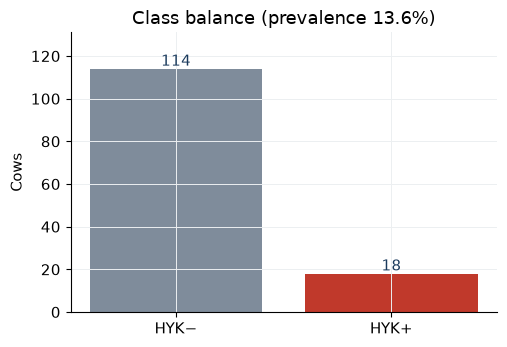

saved fig01_class_balance.png


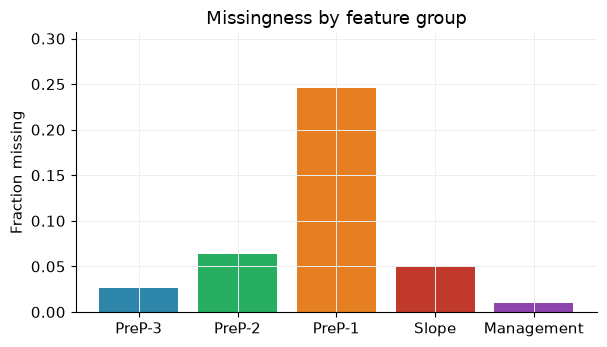

saved fig02_missingness.png


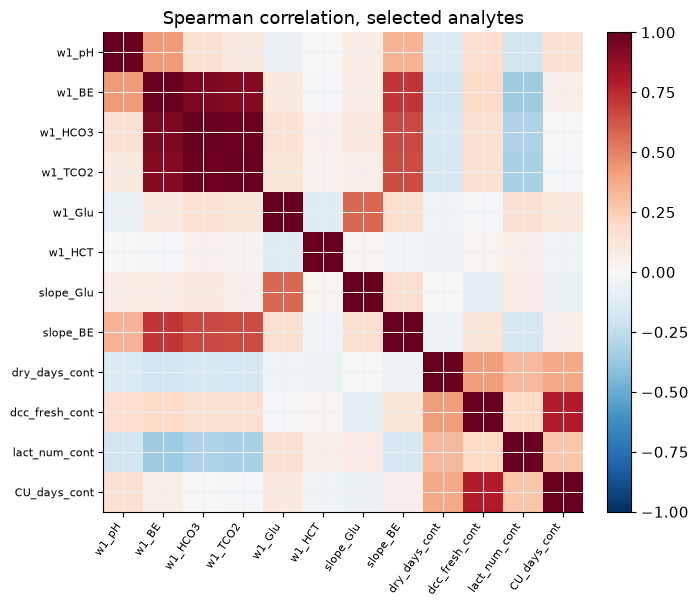

saved fig03_correlation.png


In [7]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))
counts = [int((y == 0).sum()), int(y.sum())]
bars = ax.bar(["HYK−", "HYK+"], counts, color=["#7F8C9B", "#C0392B"])
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, c + 1.5, str(c), ha="center", color=NAVY)
ax.set_ylabel("Cows")
ax.set_title(f"Class balance (prevalence {PREVALENCE:.1%})")
ax.set_ylim(0, max(counts) * 1.15)
finish(fig, "fig01_class_balance.png")

miss = pd.Series(np.isnan(X).mean(axis=0), index=feature_names)
miss_group = (
    pd.DataFrame({"group": [feature_group(n) for n in feature_names], "miss": miss.values})
    .groupby("group")["miss"].mean()
    .reindex(["PreP-3", "PreP-2", "PreP-1", "Slope", "Management"])
)
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.bar(miss_group.index, miss_group.values, color=[WEEK_COLORS[g] for g in miss_group.index])
ax.set_ylabel("Fraction missing")
ax.set_title("Missingness by feature group")
ax.set_ylim(0, max(0.05, float(miss_group.max()) * 1.25))
finish(fig, "fig02_missingness.png")

corr_names = [
    n for n in [
        "w1_pH", "w1_BE", "w1_HCO3", "w1_TCO2", "w1_Glu", "w1_HCT",
        "slope_Glu", "slope_BE", "dry_days_cont", "dcc_fresh_cont",
        "lact_num_cont", "CU_days_cont",
    ] if n in feature_names
]
corr = pd.DataFrame(X_df[corr_names]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.4, 6.2))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_names)))
ax.set_yticks(range(len(corr_names)))
ax.set_xticklabels(corr_names, rotation=55, ha="right", fontsize=8)
ax.set_yticklabels(corr_names, fontsize=8)
ax.set_title("Spearman correlation, selected analytes")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
finish(fig, "fig03_correlation.png")

## 8. Evaluation function

Every model is a pipeline: median imputation, standardization, then the classifier. The imputer and the scaler are fit inside the training fold. SMOTE, when it is used, also runs only on the training fold.

The evolutionary search does not retune the classifier. Its fitness model is L2 logistic regression with C = 0.1, the same specification that was most stable in the earlier study. One fitness evaluation is a stratified 5-fold CV on the rows the selector is allowed to see. The same folds are reused for every subset so that subset A beating subset B is not an accident of a new split.

Three objectives are minimized, which is the NSGA-II convention:

1. negative pooled PR-AUC (equivalent to maximizing PR-AUC),
2. number of features,
3. number of prepartum blood-draw weeks the subset requires.

A scalar fitness, `PR-AUC − 0.012·(number of features) − 0.02·(weeks)`, is used only for the single-objective GA, for random-search ranking, and for picking one solution off a Pareto front. NSGA-II itself never sees this weighted sum.

What the fitness ignores, on purpose: dollar cost of each analyte, biological plausibility, calibration, sensitivity at a chosen threshold, and every classifier other than logistic regression. Fold-to-fold standard deviation of PR-AUC is computed and stored, but it is not a main objective. With about three or four positive cows per fold, that standard deviation is mostly noise. A short run later checks what happens if it is optimized anyway.

In [8]:
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_lr():
    return SkPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=0.1, max_iter=2000, solver="lbfgs", random_state=SEED)),
    ])

def pooled_pr(X_sub, y_sub, cv):
    """Pooled out-of-fold PR-AUC, plus the std of the per-fold PR-AUCs."""
    if X_sub.shape[1] == 0:
        return float(np.mean(y_sub)), 0.0
    oof = cross_val_predict(make_lr(), X_sub, y_sub, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
    pr = float(average_precision_score(y_sub, oof))
    fold_prs = []
    for _, te in cv.split(X_sub, y_sub):
        if y_sub[te].sum() == 0 or y_sub[te].sum() == len(te):
            continue
        fold_prs.append(average_precision_score(y_sub[te], oof[te]))
    sd = float(np.std(fold_prs)) if fold_prs else 0.0
    return pr, sd

def make_scorer(X_sub, y_sub, cv):
    """Cache scores by the set of column indices. Cost and size do not need a model."""
    cache = {}
    n_calls = {"n": 0, "hits": 0, "seconds": 0.0}

    def score(cols):
        key = tuple(sorted(int(c) for c in cols))
        n_calls["n"] += 1
        if key in cache:
            n_calls["hits"] += 1
            return cache[key]
        t0 = time.perf_counter()
        if len(key) == 0:
            pr, sd = float(np.mean(y_sub)), 0.0
        else:
            pr, sd = pooled_pr(X_sub[:, key], y_sub, cv)
        n_calls["seconds"] += time.perf_counter() - t0
        cache[key] = (pr, sd)
        return pr, sd

    score.cache = cache
    score.stats = n_calls
    return score

def scalar_fitness(pr, n_feat, n_weeks, penalty_size=PENALTY_SIZE, penalty_week=PENALTY_WEEK):
    return float(pr - penalty_size * n_feat - penalty_week * n_weeks)

def classification_metrics(y_true, scores):
    """Threshold-free metrics, plus Youden's J operating point on these same scores."""
    out = {
        "PR-AUC": float(average_precision_score(y_true, scores)),
        "ROC-AUC": float(roc_auc_score(y_true, scores)),
    }
    fpr, tpr, thr = roc_curve(y_true, scores)
    j = tpr - fpr
    k = int(np.argmax(j))
    t = thr[k]
    if not np.isfinite(t):
        t = float(np.max(scores))
    pred = (scores >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else 0.0
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    ppv = tp / (tp + fp) if (tp + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else 0.0
    out.update({
        "Accuracy": float(accuracy_score(y_true, pred)),
        "Sensitivity": float(sens),
        "Specificity": float(spec),
        "PPV": float(ppv),
        "NPV": float(npv),
        "F1": float(f1_score(y_true, pred, zero_division=0)),
        "MCC": float(matthews_corrcoef(y_true, pred)),
        "Threshold": float(t),
    })
    return out

def build_grid_pipeline(model_name, method):
    cw = "balanced" if method == "Cost-sensitive" else None
    if model_name == "LR":
        clf = LogisticRegression(C=0.1, max_iter=2000, solver="lbfgs", random_state=SEED, class_weight=cw)
    elif model_name == "RF":
        clf = RandomForestClassifier(
            n_estimators=200, max_depth=4, min_samples_leaf=3,
            random_state=SEED, class_weight=cw, n_jobs=1,
        )
    elif model_name == "XGBoost":
        spw = (N_NEG / N_POS) if method == "Cost-sensitive" else 1.0
        clf = XGBClassifier(
            n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.9,
            eval_metric="logloss", random_state=SEED, scale_pos_weight=spw,
            verbosity=0, n_jobs=1,
        )
    elif model_name == "SVM":
        # decision_function is the ranking score. Platt scaling is unnecessary for PR-AUC
        # and dominates the runtime of a leave-one-out SVM.
        clf = SVC(kernel="rbf", C=1.0, random_state=SEED, class_weight=cw)
    else:
        raise ValueError(model_name)
    steps = [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    if method == "SMOTE":
        steps.append(("smote", SMOTE(k_neighbors=5, random_state=SEED)))
        return ImbPipeline(steps + [("clf", clf)]), "decision_function" if model_name == "SVM" else "predict_proba"
    return SkPipeline(steps + [("clf", clf)]), "decision_function" if model_name == "SVM" else "predict_proba"

def oof_scores(pipe, X_sub, y_sub, cv, method):
    try:
        out = cross_val_predict(pipe, X_sub, y_sub, cv=cv, method=method, n_jobs=-1)
    except Exception as exc:
        log(f"  parallel CV failed ({type(exc).__name__}: {exc}); retrying serial")
        out = cross_val_predict(pipe, X_sub, y_sub, cv=cv, method=method, n_jobs=1)
    if method == "predict_proba":
        out = out[:, 1]
    return np.asarray(out, dtype=float)

## 9. Classifiers without feature search

This is the "without evolutionary computation" baseline. Four model families (logistic regression, random forest, XGBoost, RBF SVM) are crossed with three imbalance strategies (none, SMOTE inside the training fold, class weighting). Each of the 12 configurations is fit to three feature sets: metabolites (60), management (10), and all 70. Validation is leave-one-out, matching the earlier HYK analysis, with preprocessing inside the fold. The question is whether the model is the bottleneck, or whether the feature set is.

In [9]:
MODEL_NAMES = ["LR"] if FAST else ["LR", "RF", "XGBoost", "SVM"]
METHOD_NAMES = ["Baseline"] if FAST else ["Baseline", "SMOTE", "Cost-sensitive"]
SET_MATRICES = {
    "Metabolites": X_df[snap_cols + slope_cols].to_numpy(dtype=float),
    "Management": X_df[list(X_mgmt.columns)].to_numpy(dtype=float),
    "Combined": X,
}

grid_rows = []
grid_scores = {}
t_grid = time.perf_counter()
for set_name, X_set in SET_MATRICES.items():
    for model_name in MODEL_NAMES:
        for method in METHOD_NAMES:
            label = f"{set_name} | {model_name} | {method}"
            log(f"LOOCV {label}")
            t0 = time.perf_counter()
            pipe, pred_method = build_grid_pipeline(model_name, method)
            try:
                scores = oof_scores(pipe, X_set, y, LeaveOneOut(), pred_method)
                metrics = classification_metrics(y, scores)
                metrics["Error"] = ""
            except Exception as exc:
                log(f"  FAILED {label}: {exc}")
                scores = np.full(len(y), PREVALENCE)
                metrics = classification_metrics(y, scores)
                metrics["Error"] = str(exc)
            metrics.update({
                "Feature set": set_name,
                "Model": model_name,
                "Strategy": method,
                "Seconds": round(time.perf_counter() - t0, 2),
            })
            grid_rows.append(metrics)
            grid_scores[(set_name, model_name, method)] = scores
            log(f"  PR-AUC={metrics['PR-AUC']:.3f}  ROC-AUC={metrics['ROC-AUC']:.3f}  ({metrics['Seconds']:.1f}s)")

grid_df = pd.DataFrame(grid_rows)
grid_df.to_csv(OUT / "model_grid_loocv.csv", index=False)
log(f"Model grid finished in {(time.perf_counter() - t_grid) / 60:.1f} min")
grid_df.sort_values("PR-AUC", ascending=False)[
    ["Feature set", "Model", "Strategy", "PR-AUC", "ROC-AUC", "Sensitivity", "Specificity", "F1", "MCC"]
].round(3).head(12)

LOOCV Metabolites | LR | Baseline


  PR-AUC=0.091  ROC-AUC=0.249  (10.4s)


LOOCV Metabolites | LR | SMOTE


  PR-AUC=0.107  ROC-AUC=0.293  (2.0s)


LOOCV Metabolites | LR | Cost-sensitive


  PR-AUC=0.094  ROC-AUC=0.265  (0.2s)


... (64 outputs left out)

LOOCV Combined | SVM | Cost-sensitive


  PR-AUC=0.239  ROC-AUC=0.586  (0.2s)


Model grid finished in 1.2 min


,Feature set,Model,Strategy,PR-AUC,ROC-AUC,Sensitivity,Specificity,F1,MCC
13,Management,LR,SMOTE,0.481,0.757,0.778,0.781,0.491,0.420
14,Management,LR,Cost-sensitive,0.462,0.763,0.778,0.781,0.491,0.420
12,Management,LR,Baseline,0.449,0.756,0.778,0.772,0.483,0.410
15,Management,RF,Baseline,0.385,0.762,0.667,0.825,0.480,0.393
19,Management,XGBoost,SMOTE,0.342,0.726,0.667,0.789,0.444,0.351
25,Combined,LR,SMOTE,0.330,0.569,0.389,0.868,0.350,0.237
22,Management,SVM,SMOTE,0.325,0.700,0.778,0.684,0.412,0.327
23,Management,SVM,Cost-sensitive,0.319,0.713,0.778,0.702,0.424,0.342
20,Management,XGBoost,Cost-sensitive,0.317,0.667,0.556,0.763,0.364,0.244
21,Management,SVM,Baseline,0.310,0.656,0.611,0.868,0.500,0.414


The heat map is the same comparison drawn as a figure. If management features beat the 60-analyte panel, and if adding the panel to the management features makes things worse, then searching for a small subset is the right problem. A more flexible model will not fix a noisy, high-dimensional sample of 18 positive cows.

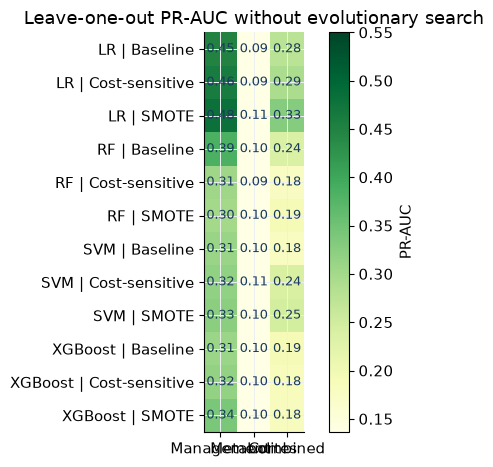

saved fig04_model_heatmap.png


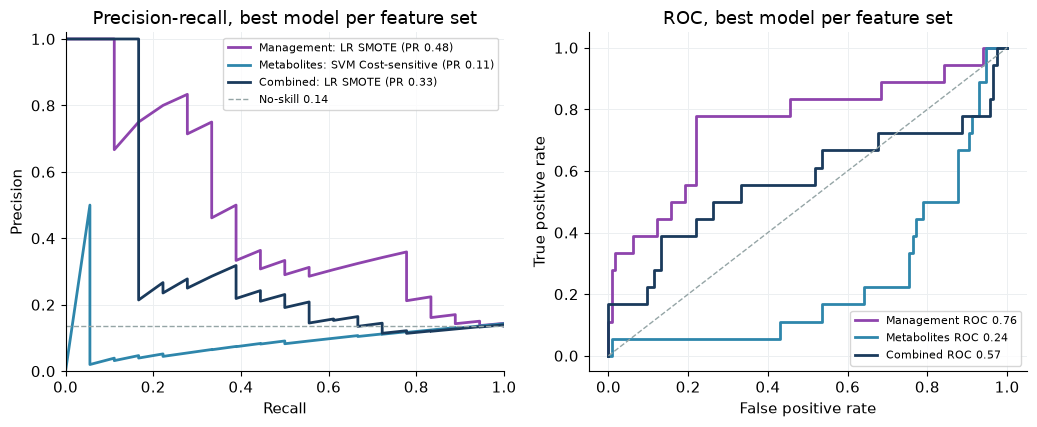

saved fig05_pr_roc_best_models.png


In [10]:
pivot = grid_df.pivot_table(index=["Model", "Strategy"], columns="Feature set", values="PR-AUC")
pivot = pivot.reindex(columns=[c for c in ["Management", "Metabolites", "Combined"] if c in pivot.columns])
fig, ax = plt.subplots(figsize=(7.2, 4.8))
im = ax.imshow(pivot.values, cmap="YlGn", vmin=PREVALENCE, vmax=max(0.55, float(np.nanmax(pivot.values))))
ax.set_xticks(range(pivot.shape[1]))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(pivot.shape[0]))
ax.set_yticklabels([f"{m} | {s}" for m, s in pivot.index])
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        val = pivot.values[i, j]
        if np.isfinite(val):
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9, color=NAVY)
ax.set_title("Leave-one-out PR-AUC without evolutionary search")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="PR-AUC")
finish(fig, "fig04_model_heatmap.png")

# PR and ROC curves for the best configuration of each feature set.
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
for set_name, color in zip(
    ["Management", "Metabolites", "Combined"],
    ["#8E44AD", "#2E86AB", "#1A3A5C"],
):
    sub = grid_df[grid_df["Feature set"] == set_name].sort_values("PR-AUC", ascending=False).iloc[0]
    scores = grid_scores[(set_name, sub["Model"], sub["Strategy"])]
    prec, rec, _ = precision_recall_curve(y, scores)
    fpr, tpr, _ = roc_curve(y, scores)
    label = f"{set_name}: {sub['Model']} {sub['Strategy']} (PR {sub['PR-AUC']:.2f})"
    axes[0].plot(rec, prec, color=color, lw=2, label=label)
    axes[1].plot(fpr, tpr, color=color, lw=2, label=f"{set_name} ROC {sub['ROC-AUC']:.2f}")
axes[0].axhline(PREVALENCE, color="#95A5A6", ls="--", lw=1, label=f"No-skill {PREVALENCE:.2f}")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-recall, best model per feature set")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)
axes[0].legend(fontsize=8, loc="upper right")
axes[1].plot([0, 1], [0, 1], color="#95A5A6", ls="--", lw=1)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC, best model per feature set")
axes[1].legend(fontsize=8, loc="lower right")
finish(fig, "fig05_pr_roc_best_models.png")

## 10. Classical subset selection

Three non-evolutionary selectors are the direct competitors.

Greedy forward selection starts from the empty set and adds the feature that most improves 5-fold PR-AUC, stopping after 8 features or when the gain drops below 0.002. It cannot swap an early choice for a better partner.

L1 logistic regression shrinks coefficients and drops features whose coefficient hits zero. The penalty (`C = 0.3`) was fixed before looking at the nested scores.

Coefficient ranking fits one L2 logistic regression on all 70 standardized features and keeps the seven largest absolute coefficients. For a linear model this is the same idea as a mean-absolute SHAP ranking: both order features by a weight from one fitted model, and neither scores combinations.

The seven-feature subset reported by the earlier leave-one-out forward selection (dry days, week −2 base excess, week −1 hematocrit, the long-dry indicator, glucose slope, gestation length, and the short-dry indicator) is rescored here. It is not re-selected. It is a published answer, not a procedure.

In [11]:
def forward_select(score, n_features, max_steps=MAX_FORWARD_STEPS, tol=FORWARD_TOL, verbose=True):
    remaining = list(range(n_features))
    selected = []
    path = []
    prev = PREVALENCE
    for step in range(max_steps):
        best_pr, best_j = -1.0, None
        for j in remaining:
            pr, _ = score(selected + [j])
            if pr > best_pr:
                best_pr, best_j = pr, j
        if best_j is None:
            break
        if selected and best_pr - prev < tol:
            if verbose:
                log(f"  forward stop at step {step + 1}: gain {best_pr - prev:.4f} < {tol}")
            break
        selected.append(best_j)
        remaining.remove(best_j)
        path.append((feature_names[best_j], best_pr))
        prev = best_pr
        if verbose:
            log(f"  step {step + 1}: + {feature_names[best_j]:24s} PR-AUC={best_pr:.3f}")
    return selected, path

def l1_select(X_sub, y_sub, C=0.3):
    pipe = SkPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            solver="liblinear", penalty="l1", C=C, max_iter=2000, random_state=SEED,
        )),
    ])
    pipe.fit(X_sub, y_sub)
    coef = pipe.named_steps["clf"].coef_.ravel()
    return list(np.flatnonzero(np.abs(coef) > 1e-8))

def coef_topk(X_sub, y_sub, k=7):
    pipe = make_lr()
    pipe.fit(X_sub, y_sub)
    coef = np.abs(pipe.named_steps["clf"].coef_.ravel())
    order = np.argsort(-coef)
    return list(order[:k])

full_scorer = make_scorer(X, y, CV5)
log("Greedy forward selection on all 70 features (5-fold PR-AUC)")
greedy_idx, greedy_path = forward_select(full_scorer, p)
l1_idx = l1_select(X, y)
coef_idx = coef_topk(X, y, k=7)
log(f"L1 kept {len(l1_idx)} features")
log("Top-7 |coefficient|: " + ", ".join(names_of(coef_idx)))
log("Greedy: " + ", ".join(names_of(greedy_idx)))

Greedy forward selection on all 70 features (5-fold PR-AUC)


  step 1: + dry_days_cont            PR-AUC=0.519


  step 2: + slope_BHBA               PR-AUC=0.528


  step 3: + w3_Urine_pH              PR-AUC=0.537


  step 4: + slope_HCT                PR-AUC=0.547


  step 5: + dcc_fresh_gt294          PR-AUC=0.552


... (2 outputs left out)

  step 8: + w3_iCa                   PR-AUC=0.579


L1 kept 8 features


Top-7 |coefficient|: dry_days_cont, dry_days_gt60, dcc_fresh_gt294, w1_SO2, CU_days_lt28, w3_pH, w3_Glu


Greedy: dry_days_cont, slope_BHBA, w3_Urine_pH, slope_HCT, dcc_fresh_gt294, dry_days_gt60, slope_Na, w3_iCa


The forward-selection path shows how much of the gain arrives with the first few features. Later additions are where a greedy rule is most likely to have already locked in a weak feature.

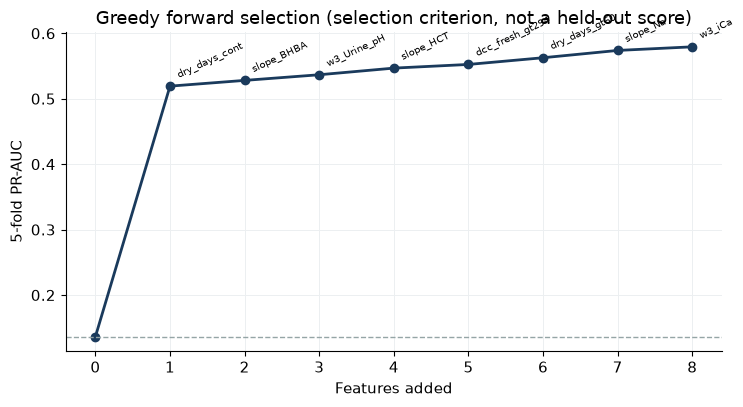

saved fig06_forward_selection.png


In [12]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
xs = list(range(0, len(greedy_path) + 1))
ys = [PREVALENCE] + [pr for _, pr in greedy_path]
ax.plot(xs, ys, marker="o", color=NAVY, lw=2)
for i, (name, _) in enumerate(greedy_path, start=1):
    ax.annotate(name, (i, ys[i]), textcoords="offset points", xytext=(4, 6), fontsize=7, rotation=25)
ax.axhline(PREVALENCE, color="#95A5A6", ls="--", lw=1)
ax.set_xlabel("Features added")
ax.set_ylabel("5-fold PR-AUC")
ax.set_title("Greedy forward selection (selection criterion, not a held-out score)")
finish(fig, "fig06_forward_selection.png")

## 11. Representation and operators

The main representation is a binary string of length 70. A 1 means the feature is in the subset. The string is initialized sparse: most individuals use 1 to 8 features, some use a moderate block, and a few use a large block, so the search actually evaluates the large subsets that the earlier study found unhelpful. The empty string is repaired by turning one random bit on.

NSGA-II uses binary tournament on Pareto rank, then crowding distance. Variation is uniform crossover at rate 0.9 and a sparse mutation: with probability 0.5 drop one selected feature, and with probability 0.5 add one feature that is not selected. Textbook bit-flip at rate 1/70 is the wrong default here. On a string with only a handful of 1s, that operator turns a 0 into a 1 about (70 − k)/k times as often as it turns a 1 into a 0, so the population drifts toward large subsets and the size objective spends its selection pressure just undoing mutation. Bit-flip is still run later, as a variation, on an equal evaluation budget.

The next generation is the usual elitist merge of parents and offspring: non-dominated sorting, then crowding to fill the last front. That merge is the elitism. No extra elite list is bolted on.

The single-objective GA maximizes the scalar fitness. It uses the same crossover and mutation, tournament selection on the scalar, and mu+lambda replacement, which is also elitist. Duplicate subsets are dropped so the population cannot fill up with copies of one winner.

Two variations are there because the main operators are not the only reasonable choice. One-point crossover is the variation that respects the block column order. A week-block mutation turns an entire sampling week, the slope block, or the management block on or off in one move. A second representation fixes the subset size at k genes (feature indices), with swap mutation and a crossover that samples k indices from the union of the parents. That version cannot change the number of features, so its only objective is PR-AUC.

In [13]:
def dominates(a, b):
    return bool(np.all(a <= b) and np.any(a < b))

def fast_nondominated_sort(objs):
    n = len(objs)
    dominates_whom = [[] for _ in range(n)]
    dominated_by = np.zeros(n, dtype=int)
    fronts = [[]]
    for p_i in range(n):
        for q_i in range(n):
            if p_i == q_i:
                continue
            if dominates(objs[p_i], objs[q_i]):
                dominates_whom[p_i].append(q_i)
            elif dominates(objs[q_i], objs[p_i]):
                dominated_by[p_i] += 1
        if dominated_by[p_i] == 0:
            fronts[0].append(p_i)
    i = 0
    while fronts[i]:
        nxt = []
        for p_i in fronts[i]:
            for q_i in dominates_whom[p_i]:
                dominated_by[q_i] -= 1
                if dominated_by[q_i] == 0:
                    nxt.append(q_i)
        i += 1
        fronts.append(nxt)
    fronts.pop()
    return fronts

def crowding_distance(objs, front):
    m = objs.shape[1]
    dist = np.zeros(len(front))
    if len(front) <= 2:
        dist[:] = np.inf
        return dist
    F = objs[np.asarray(front)]
    for j in range(m):
        order = np.argsort(F[:, j])
        dist[order[0]] = np.inf
        dist[order[-1]] = np.inf
        lo, hi = F[order[0], j], F[order[-1], j]
        span = hi - lo
        if span < 1e-12:
            continue
        for k in range(1, len(front) - 1):
            dist[order[k]] += (F[order[k + 1], j] - F[order[k - 1], j]) / span
    return dist

def annotate_ranks(pop):
    objs = np.vstack([ind["obj"] for ind in pop])
    fronts = fast_nondominated_sort(objs)
    for ind in pop:
        ind["rank"] = 10**9
        ind["crowd"] = 0.0
    for r, front in enumerate(fronts):
        cd = crowding_distance(objs, front)
        for local_i, idx in enumerate(front):
            pop[idx]["rank"] = r
            pop[idx]["crowd"] = float(cd[local_i])
    return fronts

def hypervolume_2d(points, ref):
    """2-objective hypervolume for minimization. Points are (f1, f2)."""
    pts = np.asarray(points, dtype=float)
    if len(pts) == 0:
        return 0.0
    pts = pts[(pts[:, 0] < ref[0]) & (pts[:, 1] < ref[1])]
    if len(pts) == 0:
        return 0.0
    pts = pts[np.argsort(pts[:, 0], kind="mergesort")]
    nd = []
    best2 = np.inf
    for row in pts:
        if row[1] < best2 - 1e-15:
            nd.append(row)
            best2 = row[1]
    nd = np.asarray(nd)
    hv = 0.0
    for i in range(len(nd)):
        right = ref[0] if i == len(nd) - 1 else nd[i + 1, 0]
        hv += max(right - nd[i, 0], 0.0) * max(ref[1] - nd[i, 1], 0.0)
    return float(hv)

def _self_test():
    objs = np.array([[1.0, 2.0], [2.0, 1.0], [3.0, 3.0], [0.5, 0.5]])
    fronts = fast_nondominated_sort(objs)
    assert fronts[0] == [3], fronts
    assert set(fronts[1]) == {0, 1}, fronts
    assert fronts[2] == [2], fronts
    hv = hypervolume_2d(np.array([[2.0, -0.4], [5.0, -0.6]]), (10.0, 0.0))
    assert abs(hv - 4.2) < 1e-9, hv
    log("NSGA-II self-test passed")

_self_test()

def random_mask(rng, n_features):
    u = rng.random()
    if u < 0.70:
        k = int(rng.integers(1, 9))
    elif u < 0.90:
        k = int(rng.integers(9, 21))
    else:
        k = int(rng.integers(21, n_features + 1))
    k = int(min(max(k, 1), n_features))
    mask = np.zeros(n_features, dtype=int)
    mask[rng.choice(n_features, size=k, replace=False)] = 1
    return mask

def repair(mask, rng):
    mask = np.array(mask, dtype=int, copy=True)
    if mask.sum() == 0:
        mask[int(rng.integers(0, len(mask)))] = 1
    return mask

def uniform_crossover(a, b, rng, rate=CROSSOVER_RATE):
    if rng.random() > rate:
        return a.copy(), b.copy()
    swap = rng.random(len(a)) < 0.5
    c1, c2 = a.copy(), b.copy()
    c1[swap], c2[swap] = b[swap], a[swap]
    return c1, c2

def one_point_crossover(a, b, rng, rate=CROSSOVER_RATE):
    if rng.random() > rate or len(a) < 2:
        return a.copy(), b.copy()
    cut = int(rng.integers(1, len(a)))
    c1 = np.concatenate([a[:cut], b[cut:]])
    c2 = np.concatenate([b[:cut], a[cut:]])
    return c1, c2

def bitflip(mask, rng, rate):
    out = mask.copy()
    flip = rng.random(len(out)) < rate
    out[flip] = 1 - out[flip]
    return out

def sparse_mutation(mask, rng):
    """Add or drop one feature, each with probability 1/2.

    Per-bit mutation at rate 1/L mostly inserts features when the subset is small.
    This operator does not have that directional bias. If neither coin-flip fires,
    one random bit is flipped so the child is not a clone of the parent.
    """
    out = mask.copy()
    ones = np.flatnonzero(out)
    zeros = np.flatnonzero(out == 0)
    changed = False
    if len(ones) and rng.random() < 0.5:
        out[int(rng.choice(ones))] = 0
        changed = True
    if len(zeros) and rng.random() < 0.5:
        out[int(rng.choice(zeros))] = 1
        changed = True
    if not changed:
        bit = int(rng.integers(0, len(out)))
        out[bit] = 1 - out[bit]
    return out

def apply_mutation(mask, rng, kind):
    if kind == "bitflip":
        return bitflip(mask, rng, MUTATION_RATE)
    return sparse_mutation(mask, rng)

def week_block_mutate(mask, rng, rate=0.25):
    out = mask.copy()
    if rng.random() > rate:
        return out
    group_name = list(GROUPS.keys())[int(rng.integers(0, len(GROUPS)))]
    idx = np.asarray(GROUPS[group_name])
    if out[idx].any():
        out[idx] = 0
    else:
        out[idx] = 1
    return out

def evaluate_mask(mask, score, objective_mode="size_weeks"):
    cols = tuple(np.flatnonzero(mask).tolist())
    pr, sd = score(cols)
    n_feat = int(len(cols))
    n_weeks = int(weeks_touched(cols))
    if objective_mode == "size_weeks":
        obj = np.array([-pr, float(n_feat), float(n_weeks)], dtype=float)
    elif objective_mode == "size":
        obj = np.array([-pr, float(n_feat)], dtype=float)
    elif objective_mode == "size_sd":
        obj = np.array([-pr, float(n_feat), float(sd)], dtype=float)
    else:
        raise ValueError(objective_mode)
    return {
        "mask": np.asarray(mask, dtype=int).copy(),
        "cols": cols,
        "pr": float(pr),
        "sd": float(sd),
        "n_feat": n_feat,
        "weeks": n_weeks,
        "obj": obj,
        "scalar": scalar_fitness(pr, n_feat, n_weeks),
    }

def front_hypervolume(pop):
    front = [ind for ind in pop if ind.get("rank", 0) == 0]
    if not front:
        return 0.0
    pts = np.array([[ind["n_feat"], -ind["pr"]] for ind in front], dtype=float)
    return hypervolume_2d(pts, ref=(p + 1, 0.0))

def choose_from_front(pop):
    """Pick one deployed subset from the current non-dominated set.
    The front was built without the scalar. The scalar is only the decision rule.
    """
    annotate_ranks(pop)
    front = [ind for ind in pop if ind["rank"] == 0]
    if not front:
        front = list(pop)
    return max(front, key=lambda ind: ind["scalar"])

def nsga2(
    score, rng, pop_size, n_gen, crossover="uniform", use_block=False,
    objective_mode="size_weeks", mutation="sparse", record=True,
):
    cross = uniform_crossover if crossover == "uniform" else one_point_crossover
    pop = []
    history = {"fitness": [], "pr": [], "hv": [], "best_pr": []}
    for _ in range(pop_size):
        ind = evaluate_mask(repair(random_mask(rng, p), rng), score, objective_mode)
        pop.append(ind)
        if record:
            history["fitness"].append(ind["scalar"])
            history["pr"].append(ind["pr"])
    for gen in range(n_gen):
        annotate_ranks(pop)
        history["hv"].append(front_hypervolume(pop))
        history["best_pr"].append(max(ind["pr"] for ind in pop))
        offspring = []
        while len(offspring) < pop_size:
            i, j = rng.integers(0, len(pop), size=2)
            a, b = pop[int(i)], pop[int(j)]
            # Tournament on rank, then crowding. Drawn with two independent pairs.
            def tour():
                ii, jj = rng.integers(0, len(pop), size=2)
                aa, bb = pop[int(ii)], pop[int(jj)]
                if aa["rank"] != bb["rank"]:
                    return aa if aa["rank"] < bb["rank"] else bb
                return aa if aa["crowd"] >= bb["crowd"] else bb
            parent_a, parent_b = tour(), tour()
            c1, c2 = cross(parent_a["mask"], parent_b["mask"], rng)
            for child in (c1, c2):
                child = apply_mutation(child, rng, mutation)
                if use_block:
                    child = week_block_mutate(child, rng)
                child = repair(child, rng)
                ind = evaluate_mask(child, score, objective_mode)
                offspring.append(ind)
                if record:
                    history["fitness"].append(ind["scalar"])
                    history["pr"].append(ind["pr"])
                if len(offspring) >= pop_size:
                    break
        merged = pop + offspring
        annotate_ranks(merged)
        fronts = fast_nondominated_sort(np.vstack([ind["obj"] for ind in merged]))
        # annotate_ranks already set crowd; recompute fronts consistently
        next_pop = []
        for front in fronts:
            if len(next_pop) + len(front) <= pop_size:
                next_pop.extend(merged[i] for i in front)
            else:
                ordered = sorted(front, key=lambda i: merged[i]["crowd"], reverse=True)
                need = pop_size - len(next_pop)
                next_pop.extend(merged[i] for i in ordered[:need])
                break
        pop = next_pop
        if (gen + 1) % 5 == 0 or gen == 0 or gen + 1 == n_gen:
            annotate_ranks(pop)
            log(
                f"  gen {gen + 1:02d}/{n_gen}  best PR={max(ind['pr'] for ind in pop):.3f}  "
                f"knee={choose_from_front(pop)['pr']:.3f} "
                f"({choose_from_front(pop)['n_feat']} feat, {choose_from_front(pop)['weeks']} wk)  "
                f"HV={front_hypervolume(pop):.2f}"
            )
    annotate_ranks(pop)
    history["hv"].append(front_hypervolume(pop))
    history["best_pr"].append(max(ind["pr"] for ind in pop))
    return pop, history

def tournament_scalar(pop, rng):
    i, j = rng.integers(0, len(pop), size=2)
    a, b = pop[int(i)], pop[int(j)]
    return a if a["scalar"] >= b["scalar"] else b

def single_objective_ga(score, rng, pop_size, n_gen, crossover="uniform", use_block=False, mutation="sparse"):
    cross = uniform_crossover if crossover == "uniform" else one_point_crossover
    pop = [evaluate_mask(repair(random_mask(rng, p), rng), score) for _ in range(pop_size)]
    history = {
        "fitness": [ind["scalar"] for ind in pop],
        "pr": [ind["pr"] for ind in pop],
    }
    for gen in range(n_gen):
        offspring = []
        while len(offspring) < pop_size:
            c1, c2 = cross(tournament_scalar(pop, rng)["mask"], tournament_scalar(pop, rng)["mask"], rng)
            for child in (c1, c2):
                child = apply_mutation(child, rng, mutation)
                if use_block:
                    child = week_block_mutate(child, rng)
                offspring.append(evaluate_mask(repair(child, rng), score))
                history["fitness"].append(offspring[-1]["scalar"])
                history["pr"].append(offspring[-1]["pr"])
                if len(offspring) >= pop_size:
                    break
        pool = pop + offspring
        pool.sort(key=lambda ind: ind["scalar"], reverse=True)
        next_pop, seen = [], set()
        for ind in pool:
            key = ind["mask"].tobytes()
            if key in seen:
                continue
            seen.add(key)
            next_pop.append(ind)
            if len(next_pop) == pop_size:
                break
        while len(next_pop) < pop_size:
            ind = evaluate_mask(repair(random_mask(rng, p), rng), score)
            history["fitness"].append(ind["scalar"])
            history["pr"].append(ind["pr"])
            next_pop.append(ind)
        pop = next_pop
        if (gen + 1) % 5 == 0 or gen == 0 or gen + 1 == n_gen:
            best = max(pop, key=lambda ind: ind["scalar"])
            log(f"  SOGA gen {gen + 1:02d}/{n_gen}  best scalar={best['scalar']:.3f}  PR={best['pr']:.3f}  k={best['n_feat']}")
    return pop, history

def random_search(score, rng, n_trials):
    pop = []
    history = {"fitness": [], "pr": []}
    for _ in range(n_trials):
        ind = evaluate_mask(repair(random_mask(rng, p), rng), score)
        pop.append(ind)
        history["fitness"].append(ind["scalar"])
        history["pr"].append(ind["pr"])
    return pop, history

def fixed_size_ga(score, rng, k, pop_size, n_gen):
    def init():
        return rng.choice(p, size=k, replace=False)

    def evaluate(genes):
        cols = tuple(sorted(int(g) for g in genes))
        pr, sd = score(cols)
        return {
            "genes": np.array(cols, dtype=int),
            "cols": cols,
            "pr": float(pr),
            "sd": float(sd),
            "n_feat": k,
            "weeks": int(weeks_touched(cols)),
            "scalar": float(pr),
        }

    def mutate(genes):
        out = genes.copy()
        slot = int(rng.integers(0, k))
        pool = np.setdiff1d(np.arange(p), out)
        out[slot] = int(rng.choice(pool))
        return out

    def cross(a, b):
        if rng.random() > CROSSOVER_RATE:
            return a.copy(), b.copy()
        pool = np.unique(np.concatenate([a, b]))
        if len(pool) < k:
            extra = np.setdiff1d(np.arange(p), pool)
            pool = np.concatenate([pool, rng.choice(extra, size=k - len(pool), replace=False)])
        c1 = rng.choice(pool, size=k, replace=False)
        c2 = rng.choice(pool, size=k, replace=False)
        return c1, c2

    pop = [evaluate(init()) for _ in range(pop_size)]
    history = {"fitness": [ind["scalar"] for ind in pop], "pr": [ind["pr"] for ind in pop]}
    for gen in range(n_gen):
        offspring = []
        while len(offspring) < pop_size:
            i, j = rng.integers(0, len(pop), size=2)
            a = pop[int(i)] if pop[int(i)]["scalar"] >= pop[int(j)]["scalar"] else pop[int(j)]
            i, j = rng.integers(0, len(pop), size=2)
            b = pop[int(i)] if pop[int(i)]["scalar"] >= pop[int(j)]["scalar"] else pop[int(j)]
            for child in cross(a["genes"], b["genes"]):
                if rng.random() < 0.9:
                    child = mutate(child)
                offspring.append(evaluate(child))
                history["fitness"].append(offspring[-1]["scalar"])
                history["pr"].append(offspring[-1]["pr"])
                if len(offspring) >= pop_size:
                    break
        pool = sorted(pop + offspring, key=lambda ind: ind["scalar"], reverse=True)
        next_pop, seen = [], set()
        for ind in pool:
            key = ind["cols"]
            if key in seen:
                continue
            seen.add(key)
            next_pop.append(ind)
            if len(next_pop) == pop_size:
                break
        pop = next_pop
    return pop, history

def online_offline(fitness):
    f = np.asarray(fitness, dtype=float)
    best = np.maximum.accumulate(f)
    idx = np.arange(1, len(f) + 1)
    return np.cumsum(f) / idx, np.cumsum(best) / idx, best

def jaccard(a, b):
    aa, bb = set(a), set(b)
    if not aa and not bb:
        return 1.0
    return len(aa & bb) / len(aa | bb)

NSGA-II self-test passed


## 12. Full-sample search: dynamics, operators, and stability

These runs search the full cohort. Their 5-fold scores are the numbers the algorithms optimized, so they are optimistic if the same cows were used to choose and to judge the subset. They are still the right place to see online performance, offline performance, hypervolume, and whether independent runs agree. The nested section after this one is the comparison of procedures.

Online performance is the running average of every scalar fitness evaluated so far. Offline performance is the running average of the best scalar fitness seen so far. Both definitions follow De Jong. Because NSGA-II does not optimize the scalar, its curve is a view of the same search, not the quantity its selection used. Hypervolume of the (size, PR-AUC) front is the multi-objective convergence trace.

In [14]:
def run_full_sample_searches():
    n_trials = POP_SIZE * (N_GEN + 1)
    runs = {"NSGA-II": [], "Single-objective GA": [], "Random search": []}
    t0 = time.perf_counter()
    for r in range(N_RUNS):
        log(f"\n=== Full-sample run {r + 1}/{N_RUNS} ===")
        scorer = make_scorer(X, y, CV5)
        rng = np.random.default_rng(SEED + r)
        pop, hist = nsga2(scorer, rng, POP_SIZE, N_GEN)
        knee = choose_from_front(pop)
        runs["NSGA-II"].append({"pop": pop, "history": hist, "knee": knee, "stats": dict(scorer.stats)})
        log(f"NSGA-II knee: PR={knee['pr']:.3f} k={knee['n_feat']} weeks={knee['weeks']} :: {', '.join(names_of(knee['cols']))}")

        scorer = make_scorer(X, y, CV5)
        rng = np.random.default_rng(SEED + 100 + r)
        pop, hist = single_objective_ga(scorer, rng, POP_SIZE, N_GEN)
        best = max(pop, key=lambda ind: ind["scalar"])
        runs["Single-objective GA"].append({"pop": pop, "history": hist, "knee": best, "stats": dict(scorer.stats)})
        log(f"SOGA best: PR={best['pr']:.3f} k={best['n_feat']} weeks={best['weeks']}")

        scorer = make_scorer(X, y, CV5)
        rng = np.random.default_rng(SEED + 200 + r)
        pop, hist = random_search(scorer, rng, n_trials)
        best = max(pop, key=lambda ind: ind["scalar"])
        runs["Random search"].append({"pop": pop, "history": hist, "knee": best, "stats": dict(scorer.stats)})
        log(f"Random best: PR={best['pr']:.3f} k={best['n_feat']} weeks={best['weeks']}")
    runs["seconds"] = time.perf_counter() - t0
    runs["n_trials"] = n_trials
    return runs

full_runs = run_full_sample_searches()


=== Full-sample run 1/3 ===


  gen 01/30  best PR=0.491  knee=0.491 (3 feat, 1 wk)  HV=33.80


  gen 05/30  best PR=0.519  knee=0.519 (1 feat, 0 wk)  HV=36.35


  gen 10/30  best PR=0.528  knee=0.519 (1 feat, 0 wk)  HV=36.98


  gen 15/30  best PR=0.529  knee=0.519 (1 feat, 0 wk)  HV=37.01


  gen 20/30  best PR=0.537  knee=0.519 (1 feat, 0 wk)  HV=37.54


... (44 outputs left out)

  SOGA gen 25/30  best scalar=0.507  PR=0.519  k=1


  SOGA gen 30/30  best scalar=0.507  PR=0.519  k=1


SOGA best: PR=0.519 k=1 weeks=0


Random best: PR=0.519 k=1 weeks=0


Operator and objective variations use a shorter budget than the main runs, and they are compared with a main-operator run of that same short budget. A longer run would confound "the operator is better" with "it was given more evaluations."

In [15]:
def short_variation(label, runner):
    log(f"\nVariation: {label}")
    scorer = make_scorer(X, y, CV5)
    rng = np.random.default_rng(SEED + 7)
    t0 = time.perf_counter()
    result = runner(scorer, rng)
    elapsed = time.perf_counter() - t0
    result["seconds"] = elapsed
    result["stats"] = dict(scorer.stats)
    return result

var_pop = 6 if FAST else 28
var_gen = 1 if FAST else 12

variations = {
    "Uniform + sparse mutation": short_variation(
        "Uniform + sparse mutation",
        lambda scorer, rng: dict(zip(
            ["pop", "history"],
            nsga2(scorer, rng, var_pop, var_gen, crossover="uniform", mutation="sparse"),
        )),
    ),
    "Uniform + bit-flip 1/L": short_variation(
        "Uniform + bit-flip 1/L",
        lambda scorer, rng: dict(zip(
            ["pop", "history"],
            nsga2(scorer, rng, var_pop, var_gen, crossover="uniform", mutation="bitflip"),
        )),
    ),
    "One-point + sparse mutation": short_variation(
        "One-point + sparse mutation",
        lambda scorer, rng: dict(zip(
            ["pop", "history"],
            nsga2(scorer, rng, var_pop, var_gen, crossover="one-point", use_block=False),
        )),
    ),
    "Uniform + week-block": short_variation(
        "Uniform + week-block",
        lambda scorer, rng: dict(zip(
            ["pop", "history"],
            nsga2(scorer, rng, var_pop, var_gen, crossover="uniform", use_block=True),
        )),
    ),
    "Objectives: PR and size only": short_variation(
        "2-objective",
        lambda scorer, rng: dict(zip(
            ["pop", "history"],
            nsga2(scorer, rng, var_pop, var_gen, objective_mode="size"),
        )),
    ),
    "Objectives: PR, size, fold SD": short_variation(
        "SD objective",
        lambda scorer, rng: dict(zip(
            ["pop", "history"],
            nsga2(scorer, rng, var_pop, var_gen, objective_mode="size_sd"),
        )),
    ),
}
for name, res in variations.items():
    knee = choose_from_front(res["pop"])
    res["knee"] = knee
    log(f"  {name}: knee PR={knee['pr']:.3f} k={knee['n_feat']} weeks={knee['weeks']} ({res['seconds']:.1f}s)")

log("\nFixed-size GA, k=4 and k=7")
fixed_runs = {}
for k in (4, 7):
    scorer = make_scorer(X, y, CV5)
    rng = np.random.default_rng(SEED + 300 + k)
    t0 = time.perf_counter()
    pop, hist = fixed_size_ga(scorer, rng, k, POP_SIZE if not FAST else 8, N_GEN if not FAST else 1)
    best = max(pop, key=lambda ind: ind["pr"])
    fixed_runs[k] = {"pop": pop, "history": hist, "knee": best, "seconds": time.perf_counter() - t0}
    log(f"  k={k}: PR={best['pr']:.3f} weeks={best['weeks']} :: {', '.join(names_of(best['cols']))}")


Variation: Uniform + sparse mutation


  gen 01/12  best PR=0.491  knee=0.483 (5 feat, 2 wk)  HV=33.22


  gen 05/12  best PR=0.513  knee=0.513 (3 feat, 1 wk)  HV=35.46


  gen 10/12  best PR=0.527  knee=0.519 (1 feat, 0 wk)  HV=36.91


  gen 12/12  best PR=0.528  knee=0.519 (1 feat, 0 wk)  HV=36.95



Variation: Uniform + bit-flip 1/L


... (29 outputs left out)

  Objectives: PR, size, fold SD: knee PR=0.519 k=1 weeks=0 (21.4s)



Fixed-size GA, k=4 and k=7


  k=4: PR=0.545 weeks=3 :: w3_Urine_pH, slope_BHBA, dry_days_cont, dcc_fresh_gt294


  k=7: PR=0.559 weeks=3 :: w3_BE, w3_TCO2, w2_HCO3, w2_iCa, slope_HCT, dry_days_cont, dry_days_gt60


## 13. Nested comparison

Each outer fold holds out about a fifth of the cows. Selectors run only on the training cows. The chosen subset is refit on those training cows and applied to the held-out cows. Predictions from the five test folds are pooled, and one PR-AUC is computed. That is the number used to compare methods.

Fixed feature sets (all 70, management, metabolites, and the previously published seven) do not look at the training labels in order to choose columns. The published seven were chosen on this same cohort in earlier work, so their nested score is still not an external validation. It is included as a reference point, not as a claim of prospective performance.

Evolutionary selectors inside each fold use a smaller population and fewer generations than the full-sample runs. The budget is the same for NSGA-II, the single-objective GA, random search, and the fixed-size GA.

In [16]:
outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=SEED)
outer_splits = list(outer_cv.split(X, y))

def fit_predict_fold(X_tr, y_tr, X_te, cols):
    if len(cols) == 0:
        return np.full(X_te.shape[0], float(np.mean(y_tr)))
    pipe = make_lr()
    pipe.fit(X_tr[:, cols], y_tr)
    return pipe.predict_proba(X_te[:, cols])[:, 1]

def evaluate_nested(method_name, select_fn):
    log(f"\nNested: {method_name}")
    t0 = time.perf_counter()
    proba = np.zeros(len(y), dtype=float)
    fold_rows = []
    for fold, (tr, te) in enumerate(outer_splits):
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
        chosen, inner_pr = select_fn(X[tr], y[tr], inner, SEED + 1000 + fold)
        proba[te] = fit_predict_fold(X[tr], y[tr], X[te], chosen)
        fold_rows.append({
            "fold": fold,
            "n_features": len(chosen),
            "weeks": weeks_touched(chosen),
            "inner_pr": inner_pr,
            "features": ", ".join(names_of(chosen)),
        })
        log(f"  fold {fold + 1}: k={len(chosen)} weeks={weeks_touched(chosen)} inner PR={inner_pr:.3f}")
    metrics = classification_metrics(y, proba)
    metrics.update({
        "Method": method_name,
        "Seconds": round(time.perf_counter() - t0, 2),
        "Mean features": float(np.mean([r["n_features"] for r in fold_rows])),
        "Mean weeks": float(np.mean([r["weeks"] for r in fold_rows])),
        "Mean inner PR-AUC": float(np.mean([r["inner_pr"] for r in fold_rows])),
    })
    log(f"  pooled PR-AUC={metrics['PR-AUC']:.3f}  ROC-AUC={metrics['ROC-AUC']:.3f}  ({metrics['Seconds']:.1f}s)")
    return metrics, proba, fold_rows

def sel_fixed(cols):
    def _select(X_tr, y_tr, inner, seed):
        scorer = make_scorer(X_tr, y_tr, inner)
        pr, _ = scorer(cols)
        return list(cols), pr
    return _select

def sel_greedy(X_tr, y_tr, inner, seed):
    scorer = make_scorer(X_tr, y_tr, inner)
    chosen, path = forward_select(scorer, X_tr.shape[1], verbose=False)
    pr = path[-1][1] if path else PREVALENCE
    return chosen, pr

def sel_l1(X_tr, y_tr, inner, seed):
    chosen = l1_select(X_tr, y_tr)
    scorer = make_scorer(X_tr, y_tr, inner)
    pr, _ = scorer(chosen) if chosen else (float(np.mean(y_tr)), 0.0)
    return chosen, pr

def sel_coef(X_tr, y_tr, inner, seed):
    chosen = coef_topk(X_tr, y_tr, k=7)
    scorer = make_scorer(X_tr, y_tr, inner)
    pr, _ = scorer(chosen)
    return chosen, pr

def sel_nsga(X_tr, y_tr, inner, seed):
    scorer = make_scorer(X_tr, y_tr, inner)
    rng = np.random.default_rng(seed)
    pop, _ = nsga2(scorer, rng, NESTED_POP, NESTED_GEN, record=False)
    knee = choose_from_front(pop)
    return list(knee["cols"]), float(knee["pr"])

def sel_soga(X_tr, y_tr, inner, seed):
    scorer = make_scorer(X_tr, y_tr, inner)
    rng = np.random.default_rng(seed)
    pop, _ = single_objective_ga(scorer, rng, NESTED_POP, NESTED_GEN)
    best = max(pop, key=lambda ind: ind["scalar"])
    return list(best["cols"]), float(best["pr"])

def sel_random(X_tr, y_tr, inner, seed):
    scorer = make_scorer(X_tr, y_tr, inner)
    rng = np.random.default_rng(seed)
    n_trials = NESTED_POP * (NESTED_GEN + 1)
    pop, _ = random_search(scorer, rng, n_trials)
    best = max(pop, key=lambda ind: ind["scalar"])
    return list(best["cols"]), float(best["pr"])

def sel_fixed_k(X_tr, y_tr, inner, seed, k=7):
    scorer = make_scorer(X_tr, y_tr, inner)
    rng = np.random.default_rng(seed)
    pop, _ = fixed_size_ga(scorer, rng, k, NESTED_POP, NESTED_GEN)
    best = max(pop, key=lambda ind: ind["pr"])
    return list(best["cols"]), float(best["pr"])

mgmt_idx = GROUPS["Management"]
metab_idx = GROUPS["PreP-3"] + GROUPS["PreP-2"] + GROUPS["PreP-1"] + GROUPS["Slope"]

nested_plan = [
    ("All 70 features", sel_fixed(list(range(p)))),
    ("Management only", sel_fixed(mgmt_idx)),
    ("Metabolites only", sel_fixed(metab_idx)),
    ("Published 7-feature subset", sel_fixed(PUBLISHED_IDX)),
    ("Greedy forward selection", sel_greedy),
    ("L1 logistic regression", sel_l1),
    ("Top-7 |coefficient|", sel_coef),
    ("NSGA-II", sel_nsga),
    ("Single-objective GA", sel_soga),
    ("Random search", sel_random),
    ("Fixed-size GA (k=7)", lambda X_tr, y_tr, inner, seed: sel_fixed_k(X_tr, y_tr, inner, seed, k=7)),
]

nested_rows = []
nested_scores = {}
nested_folds = {}
t_nested = time.perf_counter()
for method_name, fn in nested_plan:
    metrics, proba, folds = evaluate_nested(method_name, fn)
    nested_rows.append(metrics)
    nested_scores[method_name] = proba
    nested_folds[method_name] = folds
log(f"\nNested comparison finished in {(time.perf_counter() - t_nested) / 60:.1f} min")

nested_df = pd.DataFrame(nested_rows)
nested_df.to_csv(OUT / "nested_comparison.csv", index=False)
nested_df[
    ["Method", "PR-AUC", "ROC-AUC", "Sensitivity", "Specificity", "PPV", "NPV", "F1", "MCC",
     "Mean features", "Mean weeks", "Mean inner PR-AUC", "Seconds"]
].round(3)


Nested: All 70 features


  fold 1: k=70 weeks=3 inner PR=0.168


  fold 2: k=70 weeks=3 inner PR=0.164


  fold 3: k=70 weeks=3 inner PR=0.376


  fold 4: k=70 weeks=3 inner PR=0.293


  fold 5: k=70 weeks=3 inner PR=0.347


... (109 outputs left out)

  fold 5: k=7 weeks=3 inner PR=0.566


  pooled PR-AUC=0.352  ROC-AUC=0.720  (131.2s)



Nested comparison finished in 10.3 min


,Method,PR-AUC,ROC-AUC,Sensitivity,Specificity,PPV,NPV,F1,MCC,Mean features,Mean weeks,Mean inner PR-AUC,Seconds
0,All 70 features,0.276,0.609,0.500,0.763,0.250,0.906,0.333,0.203,70.0,3.0,0.269,0.39
1,Management only,0.493,0.789,0.778,0.772,0.350,0.957,0.483,0.410,10.0,0.0,0.428,0.35
2,Metabolites only,0.102,0.336,0.667,0.342,0.138,0.867,0.229,0.006,60.0,3.0,0.132,0.38
3,Published 7-feature subset,0.503,0.772,0.778,0.789,0.368,0.957,0.500,0.430,7.0,3.0,0.467,0.32
4,Greedy forward selection,0.420,0.764,0.889,0.649,0.286,0.974,0.432,0.374,5.6,3.0,0.563,116.57
5,L1 logistic regression,0.279,0.602,0.556,0.711,0.233,0.910,0.328,0.195,8.0,3.0,0.507,0.35
6,Top-7 |coefficient|,0.319,0.719,0.667,0.719,0.273,0.932,0.387,0.281,7.0,2.8,0.449,0.40
7,NSGA-II,0.349,0.706,0.722,0.702,0.277,0.941,0.400,0.304,2.6,1.0,0.539,119.50
8,Single-objective GA,0.504,0.830,0.833,0.728,0.326,0.965,0.469,0.404,2.0,0.0,0.498,117.45
9,Random search,0.491,0.804,0.722,0.772,0.333,0.946,0.456,0.372,2.4,1.0,0.470,132.72


## 14. Figures for the evolutionary search

The curves answer the usual evolutionary-computation questions: did the search improve on random sampling, did it keep improving late, and did the multi-objective front actually move? The bar chart is the one that should be believed when saying a method is better, because every bar is a nested PR-AUC.

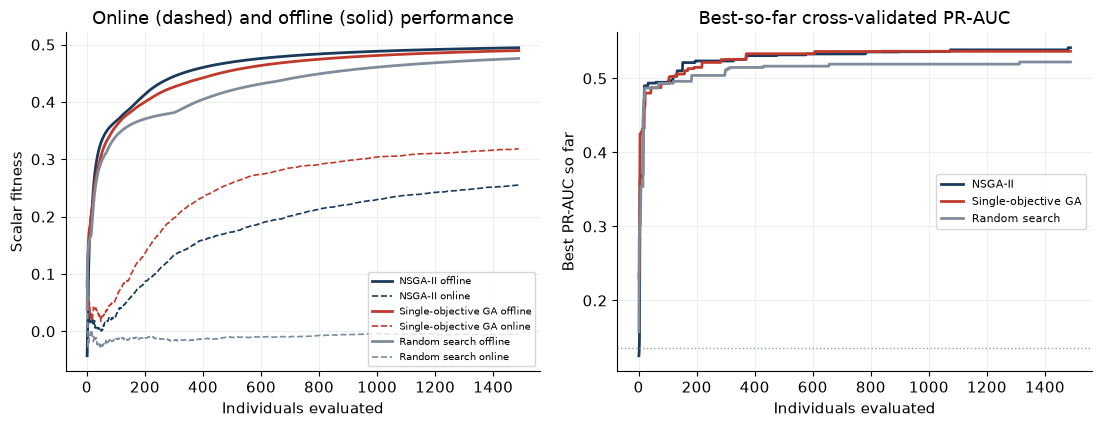

saved fig07_online_offline.png


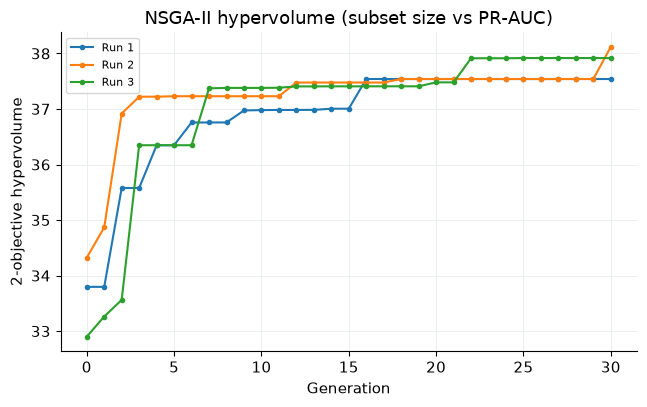

saved fig08_hypervolume.png


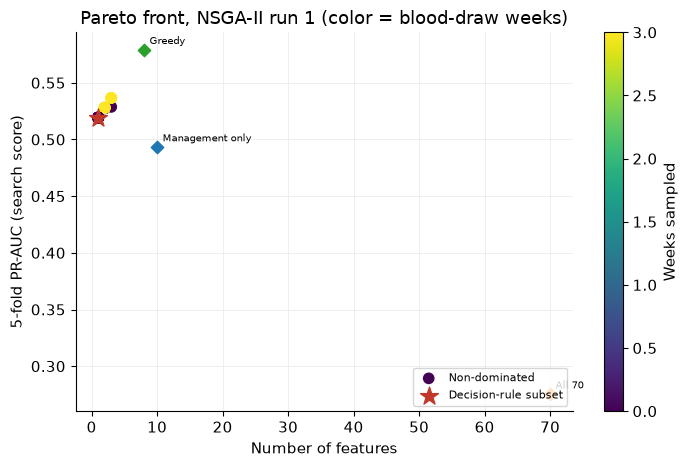

saved fig09_pareto_front.png


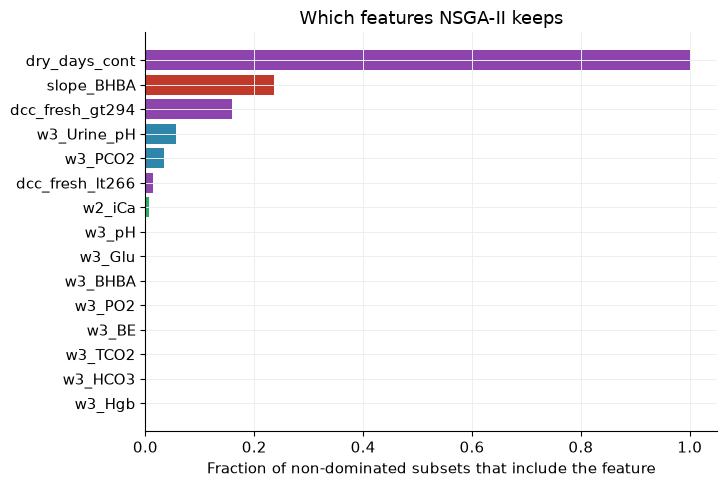

saved fig10_feature_frequency.png


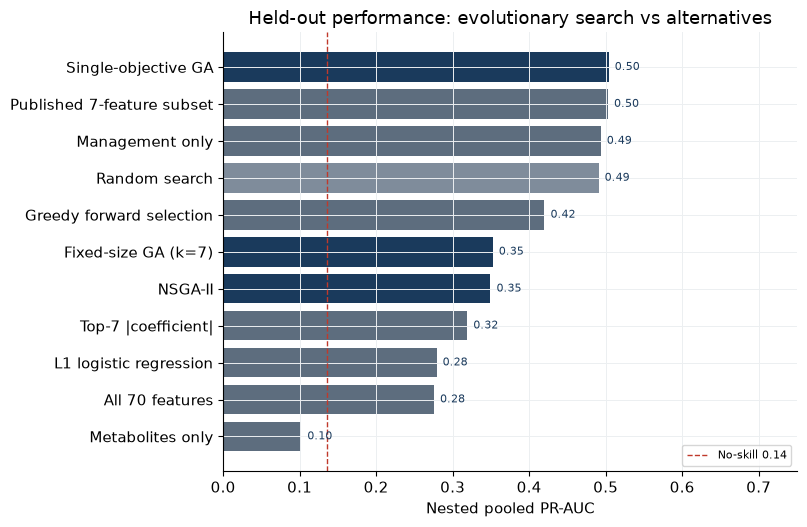

saved fig11_nested_comparison.png


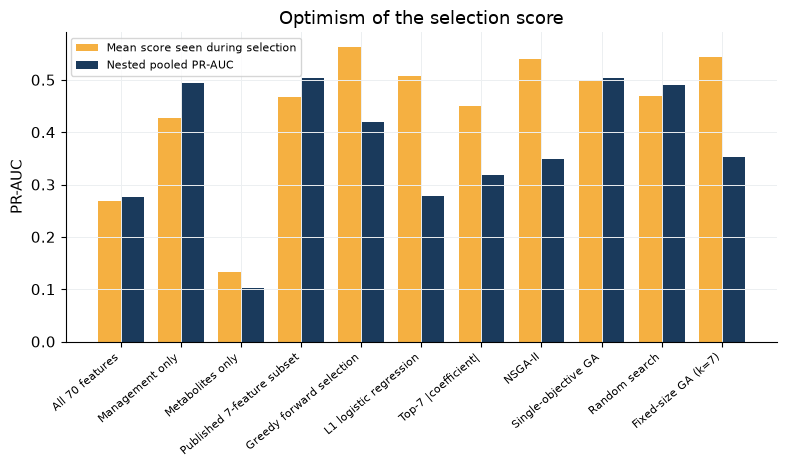

saved fig12_optimism.png


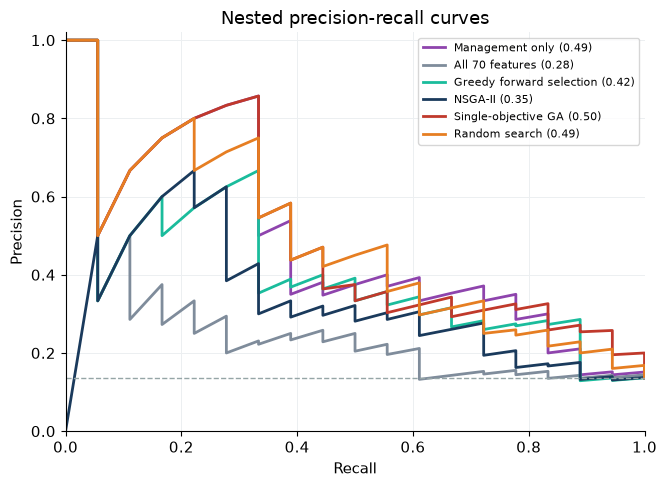

saved fig13_nested_pr_curves.png


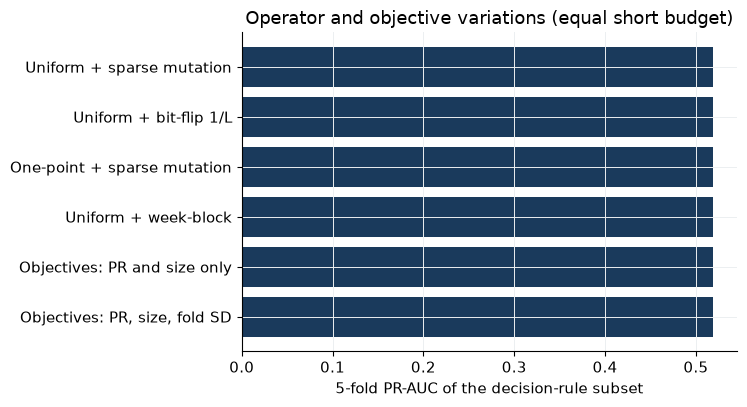

saved fig14_operator_variations.png


In [17]:
# Online / offline, averaged across independent full-sample runs.
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))
colors = {"NSGA-II": "#1A3A5C", "Single-objective GA": "#C0392B", "Random search": "#7F8C9B"}
for name, color in colors.items():
    offs, ons, bests = [], [], []
    for run in full_runs[name]:
        online, offline, best = online_offline(run["history"]["fitness"])
        ons.append(online)
        offs.append(offline)
        _, _, best_pr = online_offline(run["history"]["pr"])
        bests.append(best_pr)
    n = min(map(len, offs))
    off = np.vstack([a[:n] for a in offs]).mean(axis=0)
    on = np.vstack([a[:n] for a in ons]).mean(axis=0)
    bp = np.vstack([a[:n] for a in bests]).mean(axis=0)
    x = np.arange(1, n + 1)
    axes[0].plot(x, off, color=color, lw=2, label=f"{name} offline")
    axes[0].plot(x, on, color=color, lw=1.2, ls="--", label=f"{name} online")
    axes[1].plot(x, bp, color=color, lw=2, label=name)
axes[0].set_xlabel("Individuals evaluated")
axes[0].set_ylabel("Scalar fitness")
axes[0].set_title("Online (dashed) and offline (solid) performance")
axes[0].legend(fontsize=7, ncol=1)
axes[1].axhline(PREVALENCE, color="#95A5A6", ls=":", lw=1)
axes[1].set_xlabel("Individuals evaluated")
axes[1].set_ylabel("Best PR-AUC so far")
axes[1].set_title("Best-so-far cross-validated PR-AUC")
axes[1].legend(fontsize=8)
finish(fig, "fig07_online_offline.png")

fig, ax = plt.subplots(figsize=(6.6, 4.2))
for r, run in enumerate(full_runs["NSGA-II"]):
    hv = run["history"]["hv"]
    ax.plot(range(len(hv)), hv, marker="o", ms=3, lw=1.5, label=f"Run {r + 1}")
ax.set_xlabel("Generation")
ax.set_ylabel("2-objective hypervolume")
ax.set_title("NSGA-II hypervolume (subset size vs PR-AUC)")
ax.legend(fontsize=8)
finish(fig, "fig08_hypervolume.png")

# Pareto front from run 1, with domain baselines marked by their 5-fold scores.
scorer_ref = make_scorer(X, y, CV5)
ref_scores = {
    "Management only": scorer_ref(mgmt_idx)[0],
    "All 70": scorer_ref(list(range(p)))[0],
    "Greedy": scorer_ref(greedy_idx)[0],
}
pop0 = full_runs["NSGA-II"][0]["pop"]
annotate_ranks(pop0)
front = [ind for ind in pop0 if ind["rank"] == 0]
rest = [ind for ind in pop0 if ind["rank"] != 0]
fig, ax = plt.subplots(figsize=(7.2, 4.8))
if rest:
    ax.scatter([ind["n_feat"] for ind in rest], [ind["pr"] for ind in rest],
               c="#D0D3D4", s=28, label="Dominated")
sc = ax.scatter(
    [ind["n_feat"] for ind in front],
    [ind["pr"] for ind in front],
    c=[ind["weeks"] for ind in front],
    cmap="viridis", s=55, zorder=3, label="Non-dominated",
)
knee = full_runs["NSGA-II"][0]["knee"]
ax.scatter([knee["n_feat"]], [knee["pr"]], marker="*", s=180, color="#C0392B", zorder=4, label="Decision-rule subset")
for lab, pr in ref_scores.items():
    size = {"Management only": len(mgmt_idx), "All 70": p, "Greedy": len(greedy_idx)}[lab]
    ax.scatter([size], [pr], marker="D", s=40, zorder=4)
    ax.annotate(lab, (size, pr), textcoords="offset points", xytext=(4, 4), fontsize=7)
ax.set_xlabel("Number of features")
ax.set_ylabel("5-fold PR-AUC (search score)")
ax.set_title("Pareto front, NSGA-II run 1 (color = blood-draw weeks)")
fig.colorbar(sc, ax=ax, label="Weeks sampled")
ax.legend(fontsize=8, loc="lower right")
finish(fig, "fig09_pareto_front.png")

# Feature frequency on the final non-dominated sets.
freq = pd.Series(0, index=feature_names, dtype=float)
n_front = 0
for run in full_runs["NSGA-II"]:
    annotate_ranks(run["pop"])
    for ind in run["pop"]:
        if ind["rank"] == 0:
            n_front += 1
            for i in ind["cols"]:
                freq.iloc[i] += 1
freq = freq / max(n_front, 1)
top = freq.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7.4, 5.0))
ax.barh(
    top.index[::-1],
    top.values[::-1],
    color=[WEEK_COLORS[feature_group(n)] for n in top.index[::-1]],
)
ax.set_xlabel("Fraction of non-dominated subsets that include the feature")
ax.set_title("Which features NSGA-II keeps")
finish(fig, "fig10_feature_frequency.png")

# Nested bars.
order = nested_df.sort_values("PR-AUC", ascending=True)
fig, ax = plt.subplots(figsize=(8.2, 5.4))
bar_colors = []
for method in order["Method"]:
    if method in ("NSGA-II", "Single-objective GA", "Fixed-size GA (k=7)"):
        bar_colors.append("#1A3A5C")
    elif method == "Random search":
        bar_colors.append("#7F8C9B")
    else:
        bar_colors.append("#5D6D7E")
ax.barh(order["Method"], order["PR-AUC"], color=bar_colors)
ax.axvline(PREVALENCE, color="#C0392B", ls="--", lw=1, label=f"No-skill {PREVALENCE:.2f}")
ax.set_xlabel("Nested pooled PR-AUC")
ax.set_title("Held-out performance: evolutionary search vs alternatives")
for y_pos, val in enumerate(order["PR-AUC"]):
    ax.text(val + 0.008, y_pos, f"{val:.2f}", va="center", fontsize=8, color=NAVY)
ax.set_xlim(0, max(0.75, float(order["PR-AUC"].max()) + 0.12))
ax.legend(fontsize=8, loc="lower right")
finish(fig, "fig11_nested_comparison.png")

# Optimism: inner selection score vs nested PR-AUC.
fig, ax = plt.subplots(figsize=(8.0, 4.8))
x = np.arange(len(nested_df))
w = 0.38
ax.bar(x - w / 2, nested_df["Mean inner PR-AUC"], width=w, color="#F5B041", label="Mean score seen during selection")
ax.bar(x + w / 2, nested_df["PR-AUC"], width=w, color=NAVY, label="Nested pooled PR-AUC")
ax.set_xticks(x)
ax.set_xticklabels(nested_df["Method"], rotation=40, ha="right", fontsize=8)
ax.set_ylabel("PR-AUC")
ax.set_title("Optimism of the selection score")
ax.legend(fontsize=8)
finish(fig, "fig12_optimism.png")

# Nested PR curves for a readable subset of methods.
fig, ax = plt.subplots(figsize=(6.8, 5.0))
curve_methods = [
    "Management only", "All 70 features", "Greedy forward selection",
    "NSGA-II", "Single-objective GA", "Random search",
]
curve_colors = ["#8E44AD", "#7F8C9B", "#1ABC9C", "#1A3A5C", "#C0392B", "#E67E22"]
for method, color in zip(curve_methods, curve_colors):
    prec, rec, _ = precision_recall_curve(y, nested_scores[method])
    pr = float(nested_df.loc[nested_df["Method"] == method, "PR-AUC"].iloc[0])
    ax.plot(rec, prec, color=color, lw=2, label=f"{method} ({pr:.2f})")
ax.axhline(PREVALENCE, color="#95A5A6", ls="--", lw=1)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_title("Nested precision-recall curves")
ax.legend(fontsize=8, loc="upper right")
finish(fig, "fig13_nested_pr_curves.png")

# Operator variation: knee PR and hypervolume on the short budget.
var_rows = []
fig, ax = plt.subplots(figsize=(7.6, 4.2))
labels, prs = [], []
for name, res in variations.items():
    annotate_ranks(res["pop"])
    labels.append(name)
    prs.append(res["knee"]["pr"])
    var_rows.append({
        "Variation": name,
        "Knee PR-AUC": res["knee"]["pr"],
        "Features": res["knee"]["n_feat"],
        "Weeks": res["knee"]["weeks"],
        "Hypervolume": front_hypervolume(res["pop"]),
        "Seconds": res["seconds"],
        "Features list": ", ".join(names_of(res["knee"]["cols"])),
    })
ax.barh(labels[::-1], prs[::-1], color=NAVY)
ax.set_xlabel("5-fold PR-AUC of the decision-rule subset")
ax.set_title("Operator and objective variations (equal short budget)")
finish(fig, "fig14_operator_variations.png")
pd.DataFrame(var_rows).to_csv(OUT / "operator_variations.csv", index=False)

## 15. Stability, timing, and the subset the decision rule would ship

Independent runs do not have to return the same features. With correlated analytes and 18 positive cows, a lot of subsets are nearly tied. Agreement is the average pairwise Jaccard index of the decision-rule subsets. The frequency plot above is the better description of "what the search found" when the exact subset moves around.

In [18]:
knees = [set(run["knee"]["cols"]) for run in full_runs["NSGA-II"]]
pair_j = []
for i in range(len(knees)):
    for j in range(i + 1, len(knees)):
        pair_j.append(jaccard(knees[i], knees[j]))
jaccard_mean = float(np.mean(pair_j)) if pair_j else 1.0
log(f"NSGA-II decision-subset Jaccard across runs: {jaccard_mean:.3f}")
for r, run in enumerate(full_runs["NSGA-II"]):
    ind = run["knee"]
    log(f"  run {r + 1}: PR={ind['pr']:.3f} k={ind['n_feat']} wk={ind['weeks']} | {', '.join(names_of(ind['cols']))}")

# Leave-one-out rescore of a few subsets chosen on the full sample.
# This matches the earlier paper's protocol. It is not nested.
rescore_sets = {
    "Management only": mgmt_idx,
    "Metabolites only": metab_idx,
    "All 70 features": list(range(p)),
    "Greedy forward (full sample)": greedy_idx,
    "L1 (full sample)": l1_idx,
    "Top-7 |coefficient| (full sample)": coef_idx,
    "Published 7-feature subset": PUBLISHED_IDX,
    "NSGA-II run 1 decision subset": list(full_runs["NSGA-II"][0]["knee"]["cols"]),
    "SOGA run 1 subset": list(full_runs["Single-objective GA"][0]["knee"]["cols"]),
    "Fixed-size k=7 subset": list(fixed_runs[7]["knee"]["cols"]),
}
loo_rows = []
log("\nLeave-one-out rescore of full-sample subsets")
for name, cols in rescore_sets.items():
    if len(cols) == 0:
        scores = np.full(len(y), PREVALENCE)
    else:
        scores = oof_scores(make_lr(), X[:, cols], y, LeaveOneOut(), "predict_proba")
    met = classification_metrics(y, scores)
    met["Subset"] = name
    met["Features"] = len(cols)
    met["Weeks"] = weeks_touched(cols)
    loo_rows.append(met)
    log(f"  {name}: LOOCV PR-AUC={met['PR-AUC']:.3f} ROC-AUC={met['ROC-AUC']:.3f} k={len(cols)}")
loo_df = pd.DataFrame(loo_rows)
loo_df.to_csv(OUT / "loocv_rescore.csv", index=False)

# Timing / complexity summary.
eval_times = []
for name in ["NSGA-II", "Single-objective GA", "Random search"]:
    for run in full_runs[name]:
        st = run["stats"]
        unique = st["n"] - st["hits"]
        if unique > 0:
            eval_times.append(st["seconds"] / unique)
sec_per_eval = float(np.mean(eval_times)) if eval_times else float("nan")

summary = {
    "n_cows": int(len(y)),
    "n_positive": N_POS,
    "prevalence": PREVALENCE,
    "n_features": p,
    "fast": FAST,
    "pop_size": POP_SIZE,
    "n_generations": N_GEN,
    "n_runs": N_RUNS,
    "nested_pop": NESTED_POP,
    "nested_generations": NESTED_GEN,
    "individuals_per_full_run": int(full_runs["n_trials"]),
    "penalty_size": PENALTY_SIZE,
    "penalty_week": PENALTY_WEEK,
    "mutation_rate": MUTATION_RATE,
    "crossover_rate": CROSSOVER_RATE,
    "seconds_per_unique_evaluation": sec_per_eval,
    "full_search_seconds": full_runs["seconds"],
    "nsga_jaccard": jaccard_mean,
    "greedy_features": names_of(greedy_idx),
    "greedy_path": [{"feature": n, "pr_auc": pr} for n, pr in greedy_path],
    "published_features": PUBLISHED,
    "nsga_run1_features": names_of(full_runs["NSGA-II"][0]["knee"]["cols"]),
    "nsga_run1_search_pr": full_runs["NSGA-II"][0]["knee"]["pr"],
    "search_space": int(2 ** p) if p < 31 else "2^70",
    "nested": nested_df[["Method", "PR-AUC", "ROC-AUC", "Sensitivity", "Specificity",
                         "PPV", "NPV", "F1", "MCC", "Mean features", "Mean weeks",
                         "Mean inner PR-AUC", "Seconds"]].to_dict(orient="records"),
    "loocv_rescore": loo_df[["Subset", "PR-AUC", "ROC-AUC", "Sensitivity", "Specificity",
                             "F1", "MCC", "Features", "Weeks"]].to_dict(orient="records"),
    "model_grid_top": grid_df.sort_values("PR-AUC", ascending=False).head(8)[
        ["Feature set", "Model", "Strategy", "PR-AUC", "ROC-AUC", "Sensitivity", "Specificity", "F1"]
    ].to_dict(orient="records"),
    "operator_variations": var_rows,
    "fixed_k": {
        str(k): {
            "pr": fixed_runs[k]["knee"]["pr"],
            "weeks": fixed_runs[k]["knee"]["weeks"],
            "features": names_of(fixed_runs[k]["knee"]["cols"]),
            "seconds": fixed_runs[k]["seconds"],
        }
        for k in fixed_runs
    },
}
# JSON cannot hold a raw 2**70 easily as int beyond some encoders; store as string.
summary["search_space"] = "2^70"

def _jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, float) and not np.isfinite(obj):
        return None
    return obj

with open(OUT / "summary.json", "w", encoding="utf-8") as f:
    json.dump(_jsonable(summary), f, indent=2)

log("\n========== NESTED RESULTS ==========")
log(nested_df[["Method", "PR-AUC", "ROC-AUC", "Mean features", "Mean weeks", "Mean inner PR-AUC"]].round(3).to_string(index=False))
log("\n========== LOOCV RESCORE ==========")
log(loo_df[["Subset", "PR-AUC", "ROC-AUC", "Features", "Weeks"]].round(3).to_string(index=False))
log(f"\nUnique fitness evaluation about {sec_per_eval:.3f} s")
log(f"Full-sample evolutionary searches: {full_runs['seconds'] / 60:.1f} min")
log(f"Artifacts written to {OUT}")

NSGA-II decision-subset Jaccard across runs: 1.000


  run 1: PR=0.519 k=1 wk=0 | dry_days_cont


  run 2: PR=0.519 k=1 wk=0 | dry_days_cont


  run 3: PR=0.519 k=1 wk=0 | dry_days_cont



Leave-one-out rescore of full-sample subsets


  Management only: LOOCV PR-AUC=0.449 ROC-AUC=0.756 k=10


... (12 outputs left out)

                           Subset  PR-AUC  ROC-AUC  Features  Weeks
                  Management only   0.449    0.756        10      0
                 Metabolites only   0.091    0.249        60      3
                  All 70 features   0.275    0.590        70      3
     Greedy forward (full sample)   0.468    0.779         8      3
                 L1 (full sample)   0.468    0.754         8      3
Top-7 |coefficient| (full sample)   0.442    0.787         7      2
       Published 7-feature subset   0.456    0.752         7      3
    NSGA-II run 1 decision subset   0.473    0.795         1      0
                SOGA run 1 subset   0.473    0.795         1      0
            Fixed-size k=7 subset   0.478    0.715         7      3



Unique fitness evaluation about 0.053 s


Full-sample evolutionary searches: 9.1 min


Artifacts written to D:\DRIVE Lab\metabolic_ketosis_prediction\CSE848_Evolutionary_Feature_Selection\outputs
